# ScoutIQ – Exploratory Data Analysis
Raw Transfermarkt tables → player-season snapshots. Values are Transfermarkt **market values**, not transfer fees.

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config as C
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': .25})
from src.data_loader import load_all
raw = load_all()
for k, v in raw.items(): print(f'{k:18s} shape={v.shape}')

players            shape=(50149, 26)
player_valuations  shape=(656301, 6)
appearances        shape=(1894350, 13)
games              shape=(88958, 23)
clubs              shape=(796, 17)
competitions       shape=(65, 11)


## 1. Raw data quality

In [2]:
v, a = raw['player_valuations'], raw['appearances']
print('valuation date range:', v.date.min().date(), '→', v.date.max().date())
print('duplicate (player, date) valuations:', v.duplicated(['player_id','date']).sum())
print('duplicate appearance ids:', a.appearance_id.duplicated().sum())
print('valuation min/median/max (EUR):', v.market_value_in_eur.min(), v.market_value_in_eur.median(), v.market_value_in_eur.max())
print('appearance minutes > 120:', (a.minutes_played > 120).sum())
print('players with missing height/foot:', raw['players'][['height_in_cm','foot']].isna().mean().round(3).to_dict())
print('valuations without league id:', v.player_club_domestic_competition_id.isna().mean().round(3))
print(open(C.METRICS_DIR/'data_quality.json').read())

valuation date range: 2000-01-20 → 2026-06-12
duplicate (player, date) valuations: 0


duplicate appearance ids: 0
valuation min/median/max (EUR): 0 500000.0 200000000
appearance minutes > 120: 3
players with missing height/foot: {'height_in_cm': 0.087, 'foot': 0.118}
valuations without league id: 0.142
{
  "players_valid_position": 49563,
  "covered_leagues": [
    "BE1",
    "DK1",
    "ES1",
    "FR1",
    "GB1",
    "GR1",
    "IT1",
    "L1",
    "NL1",
    "PO1",
    "RU1",
    "SC1",
    "TR1",
    "UKR1"
  ],
  "valuation_rows_raw": 656300,
  "player_season_snapshots": 259677,
  "after_league_coverage_filter": 169105,
  "after_age_filter": 168661,
  "after_min_minutes_filter": 63897,
  "final_rows": 59171,
  "final_players": 16913,
  "rows_by_split": {
    "train": 39311,
    "val": 10076,
    "test": 9784
  },
  "missing_rate": {
    "foot": 0.0083,
    "height_cm": 0.0061,
    "club_games": 0.0532,
    "club_ppg": 0.0532,
    "club_gd_pg": 0.0532,
    "availability": 0.0532,
    "value_lag1": 0.0062,
    "log_value_lag1": 0.0062,
    "log_lag1_rel": 0.0062,
   

## 2. Modelling dataset (one row per player-season)
`src/feature_engineering.py` filters to 14 leagues with appearance data, ≥450 minutes in the 365 days before the valuation date, age 15–45.

In [3]:
df = pd.read_parquet(C.SNAPSHOTS_PATH)
print(df.shape); print(df.split.value_counts().to_dict())
display(df.isna().mean().round(3)[lambda s: s>0].to_frame('missing_rate'))
display(df[['market_value_in_eur','age','minutes_90s','goals_p90','assists_p90','club_ppg']].describe().round(2))

(59171, 43)
{'train': 39311, 'val': 10076, 'test': 9784}


,missing_rate
foot,0.008
height_cm,0.006
club_games,0.053
club_ppg,0.053
club_gd_pg,0.053
availability,0.053
value_lag1,0.006
log_value_lag1,0.006
log_lag1_rel,0.006
log_value_trend,0.038


,market_value_in_eur,age,minutes_90s,goals_p90,assists_p90,club_ppg
count,5.917100e+04,59171.00,59171.00,59171.00,59171.00,56021.00
mean,5.838472e+06,27.14,19.90,0.12,0.10,1.38
std,1.189103e+07,4.21,10.06,0.16,0.11,0.43
min,2.500000e+04,16.23,5.00,0.00,0.00,0.00
25%,6.000000e+05,23.94,11.48,0.00,0.00,1.08
50%,1.600000e+06,26.85,18.76,0.06,0.06,1.31
75%,5.000000e+06,30.10,27.05,0.18,0.15,1.68
max,2.000000e+08,43.72,64.33,1.62,1.00,3.00


## 3. Target distribution
Values are strongly right-skewed (mean ≫ median) → model `log(value)`.

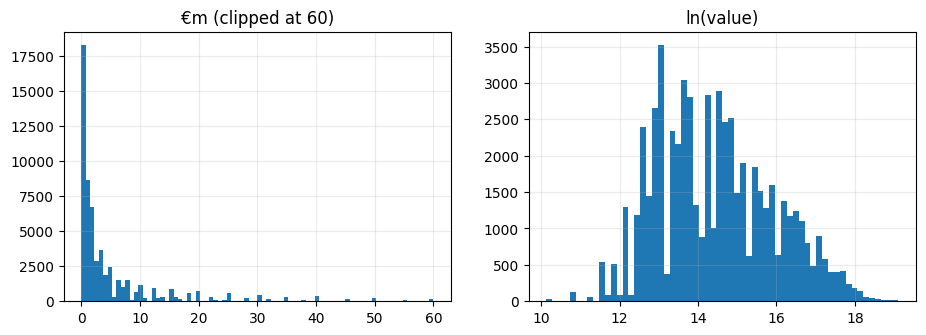

skew raw / log: 5.2 0.33


In [4]:
fig, ax = plt.subplots(1,2,figsize=(11,3.5))
ax[0].hist(df.market_value_in_eur/1e6, bins=80, range=(0,60)); ax[0].set_title('€m (clipped at 60)')
ax[1].hist(df.log_value, bins=60); ax[1].set_title('ln(value)')
plt.show()
print('skew raw / log:', round(df.market_value_in_eur.skew(),2), round(df.log_value.skew(),2))

## 4. Value by age, position, league and season

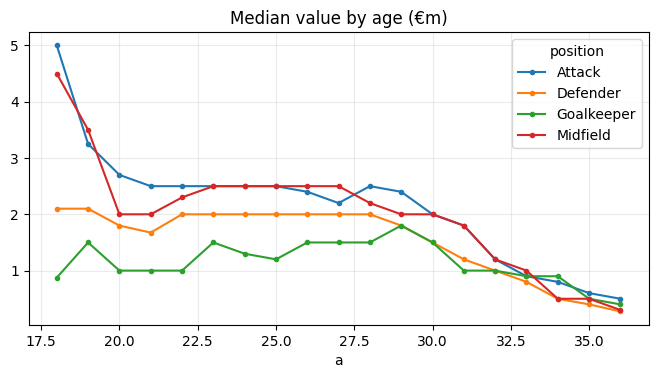

,count,median,mean
position,,,
Attack,15289.0,2.0,7.27
Defender,21650.0,1.5,4.79
Goalkeeper,4757.0,1.0,3.91
Midfield,17475.0,2.0,6.41


,median €m
league_label,
Premier League (England),12.00
Bundesliga (Germany),5.00
Serie A (Italy),4.50
Laliga (Spain),4.00
Ligue 1 (France),3.50
Super Lig (Türkiye),1.25
Jupiler Pro League (Belgium),1.20
Premier Liga (Russia),1.20
Liga Portugal (Portugal),0.90


season,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
median €m,1.3,1.25,1.25,1.5,1.5,1.6,1.7,2.0,2.0,2.0,2.5,2.5


In [5]:
g = df.assign(a=df.age.round()).groupby(['a','position']).market_value_in_eur.median().unstack().loc[18:36]/1e6
g.plot(marker='o', ms=3, figsize=(8,3.8), title='Median value by age (€m)'); plt.show()
display((df.groupby('position').market_value_in_eur.agg(['count','median','mean'])/[1,1e6,1e6]).round(2))
display((df.groupby('league_label').market_value_in_eur.median()/1e6).sort_values(ascending=False).round(2).to_frame('median €m'))
display((df.groupby('season').market_value_in_eur.median()/1e6).round(2).to_frame('median €m').T)

Among regular players (≥450 minutes) the median value is highest for the youngest outfield players and declines with age, falling steeply after ~30; goalkeepers peak later (~29). The early peak is partly a selection effect: teenagers who already play regularly are exceptional. The median observed value of eligible players drifts upward across seasons — the reason the model uses a prior-season market index instead of treating all seasons as exchangeable.

## 5. Playing time, output and value (Spearman, with caveats)
Correlation is not causation: playing time, club strength and league are entangled.

In [6]:
cols = ['log_value','age','minutes_90s','appearances','goals_p90','assists_p90','ga_p90','club_ppg','euro_minutes_share','availability']
corr = df[cols].corr(method='spearman')
display(corr['log_value'].round(2).to_frame('spearman vs ln(value)'))
att = df[df.position=='Attack']
print('Attackers only: spearman(ga_p90, ln value) =', round(att.ga_p90.corr(att.log_value, method='spearman'),2))
gk = df[df.position=='Goalkeeper']
print('Goalkeepers: spearman(ga_p90, ln value) =', round(gk.ga_p90.corr(gk.log_value, method='spearman'),2), '(goals/assists are not meaningful for keepers)')

,spearman vs ln(value)
log_value,1.00
age,-0.21
minutes_90s,0.45
appearances,0.53
goals_p90,0.24
assists_p90,0.25
ga_p90,0.26
club_ppg,0.44
euro_minutes_share,0.40
availability,0.24


Attackers only: spearman(ga_p90, ln value) = 0.41
Goalkeepers: spearman(ga_p90, ln value) = 0.09 (goals/assists are not meaningful for keepers)


## 6. Outliers
Extreme valuations are real (not errors), so they are kept; log-scaling limits their leverage. Implausible heights are nulled at ingestion.

In [7]:
q1, q3 = df.log_value.quantile([.25,.75]); iqr = q3-q1
print('rows beyond 1.5×IQR on log scale:', ((df.log_value > q3+1.5*iqr)|(df.log_value < q1-1.5*iqr)).sum())
display(df.nlargest(8,'market_value_in_eur')[['player_name','club_name','season','age','market_value_in_eur']])
print('goals/90 > 1.5:', (df.goals_p90>1.5).sum(), ' (small minute samples are excluded by the 450-minute rule)')

rows beyond 1.5×IQR on log scale: 51


,player_name,club_name,season,age,market_value_in_eur
24168,Kylian Mbappé,Paris Saint-Germain,2018,20.451746,200000000
53795,Lamine Yamal,FC Barcelona,2024,17.908281,200000000
56103,Erling Haaland,Manchester City,2025,25.867214,200000000
58678,Lamine Yamal,FC Barcelona,2025,18.896646,200000000
15507,Lionel Messi,FC Barcelona,2017,30.932238,180000000
16601,Neymar,Paris Saint-Germain,2017,26.327173,180000000
21132,Neymar,Paris Saint-Germain,2018,27.323751,180000000
28593,Kylian Mbappé,Paris Saint-Germain,2019,21.300480,180000000


goals/90 > 1.5: 2  (small minute samples are excluded by the 450-minute rule)


## 7. Model errors (held-out test seasons)

test rows 9784


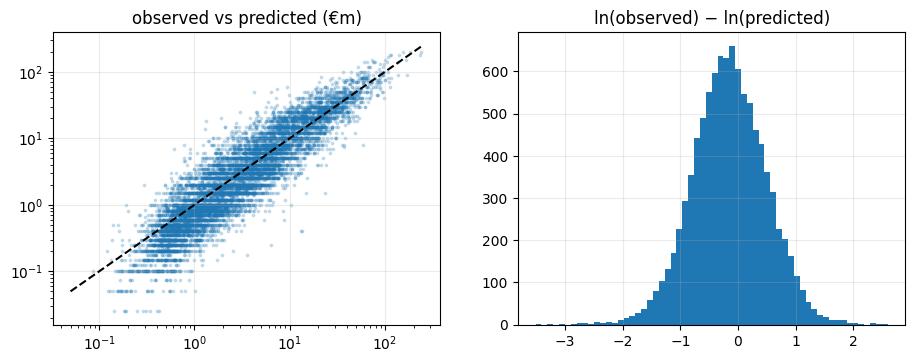

,position,n,MAE_eur,RMSE_eur,R2,MedianAPE_pct,MAE_log,median_signed_log_error
0,Attack,2621,3576944.343,7770093.991,0.815,42.984,0.528,0.161
1,Defender,3503,2642837.311,5592126.464,0.749,42.927,0.514,0.142
2,Goalkeeper,773,2064417.219,4318090.642,0.675,48.998,0.581,0.244
3,Midfield,2887,3232103.783,7273097.545,0.793,41.741,0.509,0.133


,value_band,n,MAE_eur,RMSE_eur,R2,MedianAPE_pct,MAE_log,median_signed_log_error
0,<€0.5m,1448,3.752031e+05,6.864721e+05,-36.557,112.173,0.833,0.752
1,€0.5-2m,2890,6.941222e+05,1.172850e+06,-8.228,44.033,0.489,0.309
2,€10-30m,1533,6.338564e+06,7.981837e+06,-1.189,35.048,0.466,-0.263
3,€2-10m,3264,2.094158e+06,3.271446e+06,-1.628,37.877,0.461,0.017
4,≥€30m,649,1.611441e+07,2.141594e+07,0.372,29.023,0.403,-0.245


,player_seen_in_train,n,MAE_eur,RMSE_eur,R2,MedianAPE_pct,MAE_log,median_signed_log_error
0,False,4869,2705183.281,5882966.529,0.772,44.883,0.534,0.159
1,True,4915,3334358.283,7362211.294,0.802,41.657,0.509,0.146


In [8]:
p = pd.read_parquet(C.PREDICTIONS_PATH); t = p[p.split=='test']
print('test rows', len(t))
fig, ax = plt.subplots(1,2,figsize=(11,3.8))
ax[0].scatter(t.predicted_value/1e6, t.market_value_in_eur/1e6, s=3, alpha=.2); ax[0].set(xscale='log', yscale='log', title='observed vs predicted (€m)')
ax[0].plot([.05,250],[.05,250],'k--')
ax[1].hist(t.log_residual, bins=60); ax[1].set_title('ln(observed) − ln(predicted)'); plt.show()
for f in ['error_by_position','error_by_value_band','error_by_seen_player']:
    display(pd.read_csv(C.METRICS_DIR/f'{f}.csv').round(3))